###Reconocimiento de Enfermedades Dérmicas Caninas mediante Deep Learning – PyTorch & ResNet50

In [1]:
#0. Montar Google Drive
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [2]:
#1. Configuración Inicial
import os
import random
import numpy as np
import torch

# Ruta del dataset: train, valid, test
DATA_DIR = "/content/drive/MyDrive/diplomado/proyectofinal"   # <-- CAMBIAR ESTA RUTA

IMG_SIZE = 224
BATCH_SIZE = 16
NUM_CLASSES = 6
SEED = 42
NUM_WORKERS = 4

# Reproducibilidad
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device


device(type='cuda')

In [3]:
#2. Librerías
import torch.nn as nn
import torchvision.transforms as T
from torchvision import datasets
from torch.utils.data import DataLoader


In [4]:
#3. Exploración del Dataset (EDA)
from collections import Counter

train_path = os.path.join(DATA_DIR, "train")

class_counts = {}
for cls in os.listdir(train_path):
    folder = os.path.join(train_path, cls)
    if os.path.isdir(folder):
        class_counts[cls] = len(os.listdir(folder))

class_counts


{'demodicosis': 588,
 'Dermatitis': 546,
 'Hypersensitivity': 230,
 'Fungal_infections': 375,
 'ringworm': 791,
 'Healthy': 492}

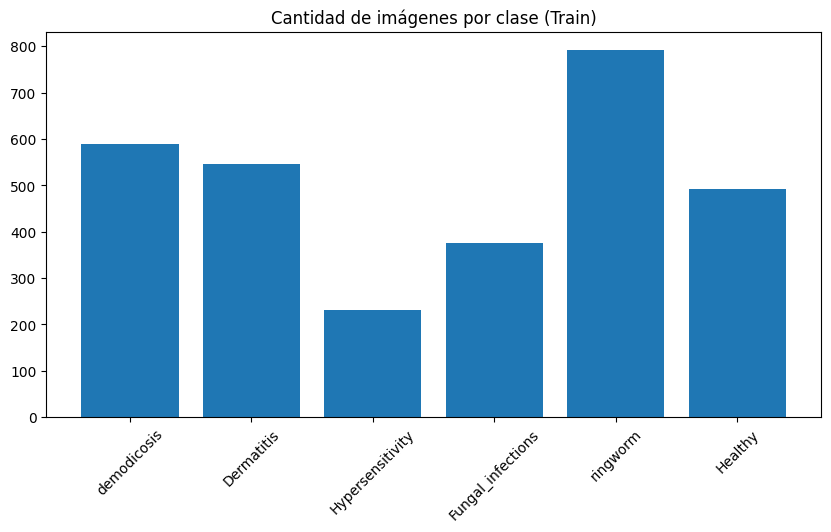

In [5]:
#Gráfico de distribución
import matplotlib.pyplot as plt

plt.figure(figsize=(10,5))
plt.bar(class_counts.keys(), class_counts.values())
plt.xticks(rotation=45)
plt.title("Cantidad de imágenes por clase (Train)")
plt.show()


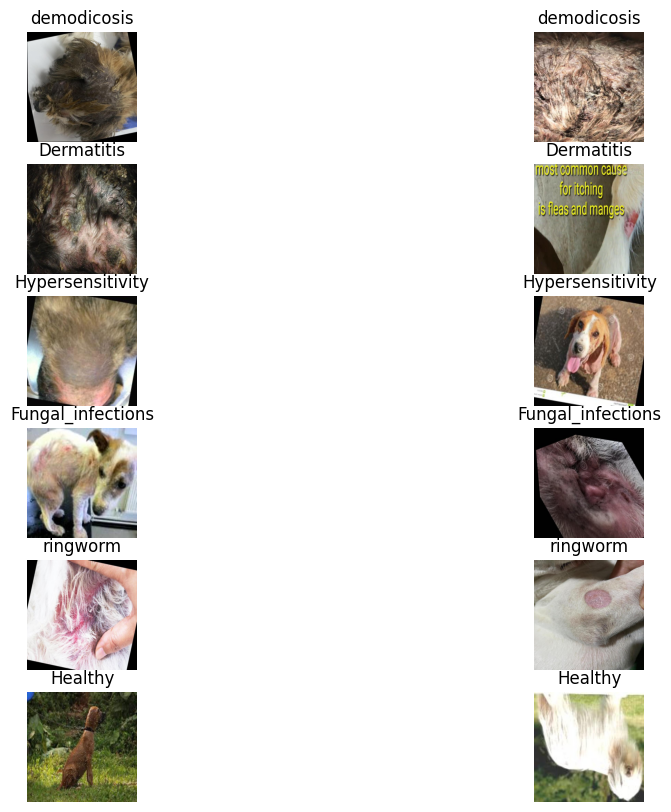

In [6]:
#Muestra visual del dataset
from PIL import Image

def show_samples(base_path, classes, n=2):
    plt.figure(figsize=(12, 10))
    idx = 1
    for cls in classes:
        cls_path = os.path.join(base_path, cls)
        imgs = os.listdir(cls_path)
        for _ in range(n):
            img = Image.open(os.path.join(cls_path, random.choice(imgs)))
            plt.subplot(len(classes), n, idx)
            plt.imshow(img)
            plt.axis("off")
            plt.title(cls)
            idx += 1

show_samples(train_path, list(class_counts.keys()))


In [7]:
#4. Data Augmentation + Loaders
train_transforms = T.Compose([
    T.Resize((IMG_SIZE, IMG_SIZE)),
    T.RandomHorizontalFlip(),
    T.RandomVerticalFlip(),
    T.RandomRotation(25),
    T.ColorJitter(0.2, 0.2, 0.2),
    T.RandomResizedCrop(IMG_SIZE, scale=(0.7, 1.0)),
    T.ToTensor(),
    T.Normalize([0.485,0.456,0.406], [0.229,0.224,0.225])
])

val_test_transforms = T.Compose([
    T.Resize((IMG_SIZE, IMG_SIZE)),
    T.ToTensor(),
    T.Normalize([0.485,0.456,0.406], [0.229,0.224,0.225])
])

train_ds = datasets.ImageFolder(os.path.join(DATA_DIR, "train"), transform=train_transforms)
val_ds   = datasets.ImageFolder(os.path.join(DATA_DIR, "valid"), transform=val_test_transforms)
test_ds  = datasets.ImageFolder(os.path.join(DATA_DIR, "test"),  transform=val_test_transforms)

class_names = train_ds.classes
class_names


['Dermatitis',
 'Fungal_infections',
 'Healthy',
 'Hypersensitivity',
 'demodicosis',
 'ringworm']

In [8]:
#5. Balanceo del dataset (WeightedRandomSampler)
targets = [label for _, label in train_ds.samples]
class_count = Counter(targets)

class_weights = {cls: 1.0/count for cls, count in class_count.items()}
sample_weights = [class_weights[t] for t in targets]
sample_weights = torch.DoubleTensor(sample_weights)

sampler = torch.utils.data.WeightedRandomSampler(sample_weights, len(sample_weights))


In [9]:
#DataLoaders
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, sampler=sampler, num_workers=NUM_WORKERS)
val_loader   = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)
test_loader  = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)


/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:627: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(


In [10]:
#6. Cargar ResNet50 preentrenada
import torchvision.models as models

model = models.resnet50(pretrained=True)
in_features = model.fc.in_features

model.fc = nn.Sequential(
    nn.Dropout(0.4),
    nn.Linear(in_features, 512),
    nn.ReLU(),
    nn.BatchNorm1d(512),
    nn.Dropout(0.3),
    nn.Linear(512, NUM_CLASSES)
)

model = model.to(device)


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet50_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet50_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 207MB/s]


In [11]:
#7. Torchsummary
!pip install torchsummary
from torchsummary import summary

summary(model, (3, 224, 224))


----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1         [-1, 64, 112, 112]           9,408
       BatchNorm2d-2         [-1, 64, 112, 112]             128
              ReLU-3         [-1, 64, 112, 112]               0
         MaxPool2d-4           [-1, 64, 56, 56]               0
            Conv2d-5           [-1, 64, 56, 56]           4,096
       BatchNorm2d-6           [-1, 64, 56, 56]             128
              ReLU-7           [-1, 64, 56, 56]               0
            Conv2d-8           [-1, 64, 56, 56]          36,864
       BatchNorm2d-9           [-1, 64, 56, 56]             128
             ReLU-10           [-1, 64, 56, 56]               0
           Conv2d-11          [-1, 256, 56, 56]          16,384
      BatchNorm2d-12          [-1, 256, 56, 56]             512
           Conv2d-13          [-1, 256, 56, 56]          16,384
      BatchNorm2d-14          [-1, 256,

In [12]:
#8. Congelar base (Fase 1)
for name, param in model.named_parameters():
    if "fc" not in name:
        param.requires_grad = False

optimizer = torch.optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=1e-3)
criterion = nn.CrossEntropyLoss()


In [13]:
#Scheduler:
from torch.optim.lr_scheduler import ReduceLROnPlateau
scheduler = ReduceLROnPlateau(optimizer, mode='max', factor=0.5, patience=3)


In [14]:
#9. Funciones: train / eval
from tqdm import tqdm

def train_one_epoch(model, loader, optimizer, criterion):
    model.train()
    loss_total, acc_total = 0, 0
    total = 0

    for x, y in tqdm(loader):
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()

        preds = model(x)
        loss = criterion(preds, y)
        loss.backward()
        optimizer.step()

        _, pred_labels = torch.max(preds, 1)
        loss_total += loss.item()*x.size(0)
        acc_total += (pred_labels == y).sum().item()
        total += x.size(0)

    return loss_total/total, acc_total/total


def eval_one_epoch(model, loader, criterion):
    model.eval()
    loss_total, acc_total = 0, 0
    total = 0

    with torch.no_grad():
        for x, y in tqdm(loader):
            x, y = x.to(device), y.to(device)

            preds = model(x)
            loss = criterion(preds, y)

            _, pred_labels = torch.max(preds, 1)
            loss_total += loss.item()*x.size(0)
            acc_total += (pred_labels == y).sum().item()
            total += x.size(0)

    return loss_total/total, acc_total/total


In [15]:
#10. Entrenamiento Fase 1 — Cabeza
EPOCHS1 = 13

history = {"train_loss":[], "train_acc":[], "val_loss":[], "val_acc":[]}
best_acc = 0
best_model = None

for epoch in range(EPOCHS1):
    print(f"\nEPOCH {epoch+1}/{EPOCHS1}")
    tl, ta = train_one_epoch(model, train_loader, optimizer, criterion)
    vl, va = eval_one_epoch(model, val_loader, criterion)
    scheduler.step(va)

    history["train_loss"].append(tl)
    history["train_acc"].append(ta)
    history["val_loss"].append(vl)
    history["val_acc"].append(va)

    print(f"Train Acc {ta:.4f} | Val Acc {va:.4f}")

    if va > best_acc:
        best_acc = va
        best_model = model.state_dict().copy()
        torch.save(best_model, "/content/resnet50_phase1.pth")



EPOCH 1/13


100%|██████████| 54/54 [01:54<00:00,  2.12s/it]


Train Acc 0.6029 | Val Acc 0.7651

EPOCH 2/13


100%|██████████| 54/54 [00:06<00:00,  8.13it/s]


Train Acc 0.6466 | Val Acc 0.7965

EPOCH 3/13


100%|██████████| 54/54 [00:08<00:00,  6.64it/s]


... (17 outputs left out)

100%|██████████| 54/54 [00:07<00:00,  7.52it/s]


Train Acc 0.7025 | Val Acc 0.8116

EPOCH 13/13


100%|██████████| 54/54 [00:07<00:00,  7.40it/s]

Train Acc 0.6985 | Val Acc 0.8174


In [16]:
#11. Fine-Tuning (Fase 2)
model.load_state_dict(best_model)

for name, param in model.named_parameters():
    if ("layer4" in name) or ("fc" in name):
        param.requires_grad = True

optimizer = torch.optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=1e-5)
scheduler = ReduceLROnPlateau(optimizer, mode='max', factor=0.5, patience=3)


In [17]:
#Entrenamiento Fase 2
EPOCHS2 = 15

for epoch in range(EPOCHS2):
    print(f"\nFine-Tune Epoch {epoch+1}/{EPOCHS2}")
    tl, ta = train_one_epoch(model, train_loader, optimizer, criterion)
    vl, va = eval_one_epoch(model, val_loader, criterion)
    scheduler.step(va)

    history["train_loss"].append(tl)
    history["train_acc"].append(ta)
    history["val_loss"].append(vl)
    history["val_acc"].append(va)

    if va > best_acc:
        best_acc = va
        best_model = model.state_dict().copy()
        torch.save(best_model, "/content/resnet50_finetuned.pth")



Fine-Tune Epoch 1/15


100%|██████████| 54/54 [00:07<00:00,  7.02it/s]



Fine-Tune Epoch 2/15


100%|██████████| 54/54 [00:06<00:00,  8.19it/s]



Fine-Tune Epoch 3/15


100%|██████████| 54/54 [00:06<00:00,  8.07it/s]


... (20 outputs left out)


Fine-Tune Epoch 14/15


100%|██████████| 54/54 [00:06<00:00,  8.26it/s]



Fine-Tune Epoch 15/15


100%|██████████| 54/54 [00:06<00:00,  8.09it/s]


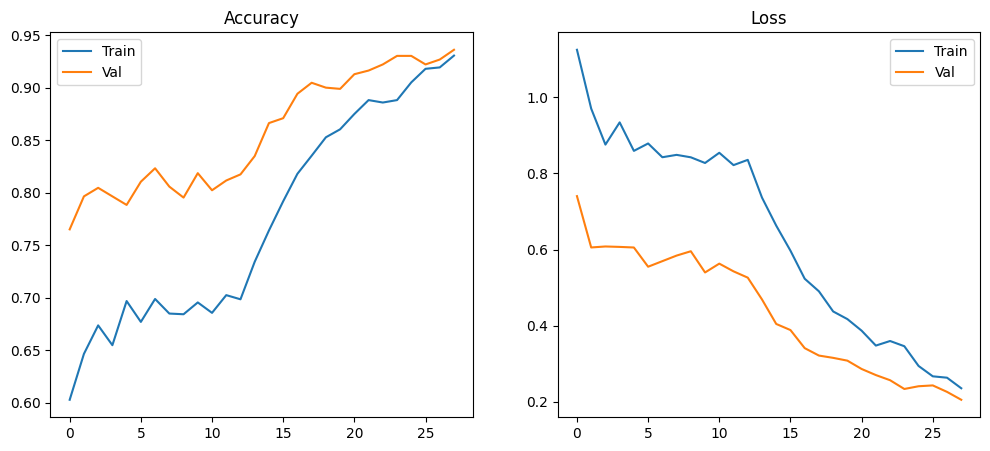

In [18]:
#12. Graficar accuracy y loss
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.plot(history["train_acc"], label="Train")
plt.plot(history["val_acc"], label="Val")
plt.title("Accuracy"); plt.legend()

plt.subplot(1,2,2)
plt.plot(history["train_loss"], label="Train")
plt.plot(history["val_loss"], label="Val")
plt.title("Loss"); plt.legend()

plt.show()


In [19]:
#13. Evaluación en Test + Classification Report
model.load_state_dict(best_model)

all_preds, all_labels = [], []

model.eval()
with torch.no_grad():
    for x, y in test_loader:
        x = x.to(device)
        preds = model(x)
        _, pred_labels = torch.max(preds,1)
        all_preds.extend(pred_labels.cpu().numpy())
        all_labels.extend(y.numpy())


In [20]:
#Reporte
from sklearn.metrics import classification_report
print(classification_report(all_labels, all_preds, target_names=class_names))


                   precision    recall  f1-score   support

       Dermatitis       0.91      0.89      0.90        66
Fungal_infections       0.88      0.83      0.86        54
          Healthy       0.92      0.96      0.94        69
 Hypersensitivity       0.97      0.97      0.97        29
      demodicosis       0.97      0.99      0.98       100
         ringworm       0.96      0.95      0.95       115

         accuracy                           0.94       433
        macro avg       0.93      0.93      0.93       433
     weighted avg       0.94      0.94      0.94       433



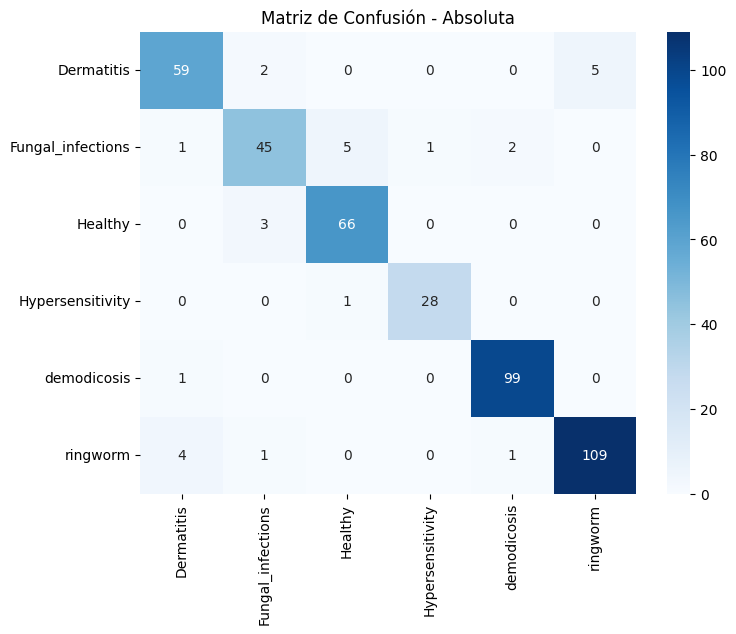

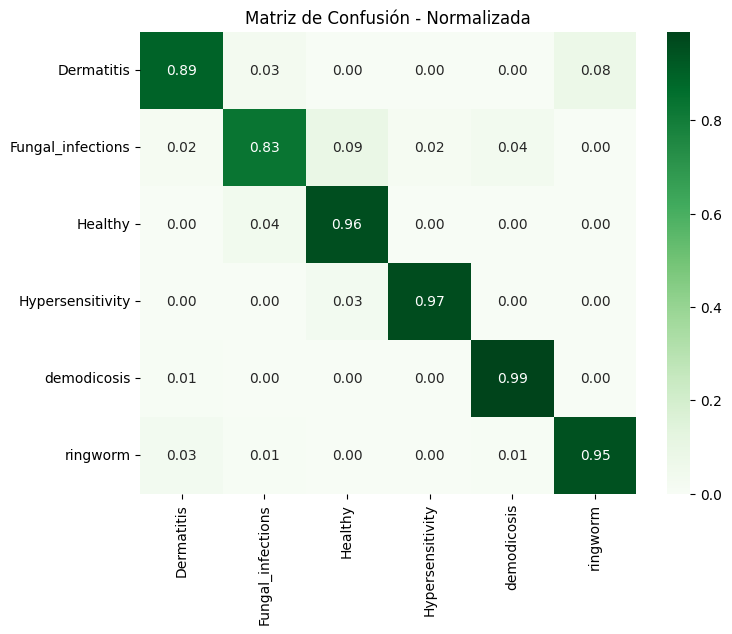

In [21]:
#14. Matriz de Confusión (absoluta + normalizada)
from sklearn.metrics import confusion_matrix
import seaborn as sns

cm = confusion_matrix(all_labels, all_preds)

plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
plt.title("Matriz de Confusión - Absoluta")
plt.show()

cm_norm = cm.astype("float") / cm.sum(axis=1)[:,None]

plt.figure(figsize=(8,6))
sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Greens", xticklabels=class_names, yticklabels=class_names)
plt.title("Matriz de Confusión - Normalizada")
plt.show()


/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:627: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(


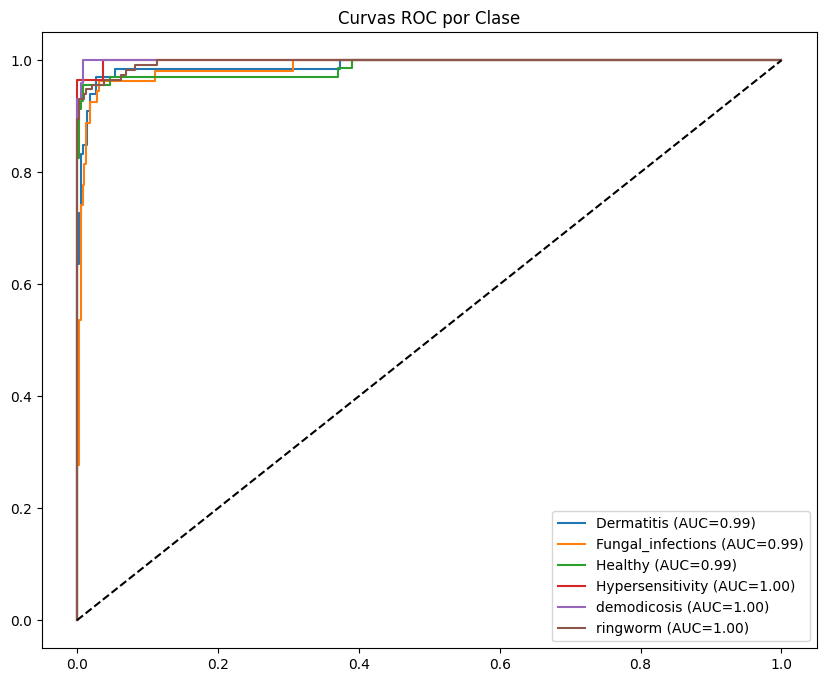

In [22]:
#15. Curvas ROC por Clase
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc

# obtener probabilidades
model.eval()
all_probs = []
all_labels = []

with torch.no_grad():
    for x, y in test_loader:
        x = x.to(device)
        probs = torch.softmax(model(x), dim=1)
        all_probs.extend(probs.cpu().numpy())
        all_labels.extend(y.numpy())

all_probs = np.array(all_probs)
all_labels = np.array(all_labels)

y_bin = label_binarize(all_labels, classes=list(range(NUM_CLASSES)))

plt.figure(figsize=(10,8))
for i in range(NUM_CLASSES):
    fpr, tpr, _ = roc_curve(y_bin[:,i], all_probs[:,i])
    roc_auc = auc(fpr,tpr)
    plt.plot(fpr, tpr, label=f"{class_names[i]} (AUC={roc_auc:.2f})")

plt.plot([0,1],[0,1],"k--")
plt.title("Curvas ROC por Clase")
plt.legend()
plt.show()


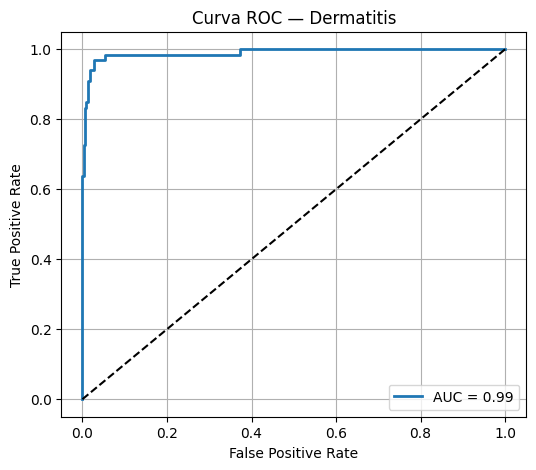

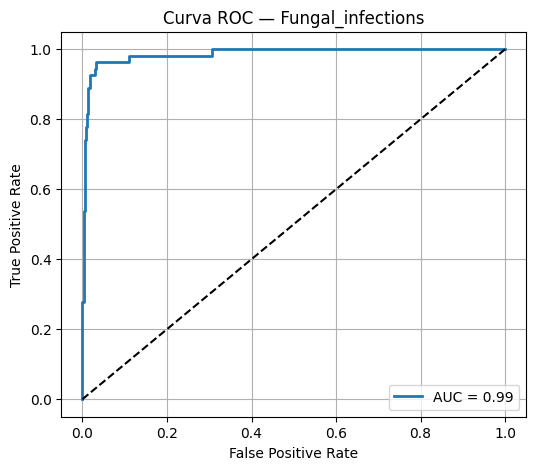

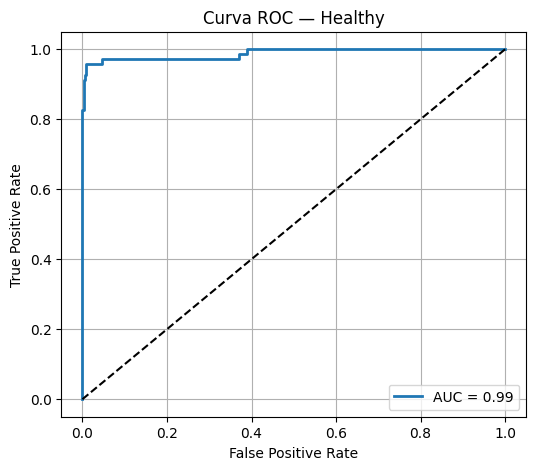

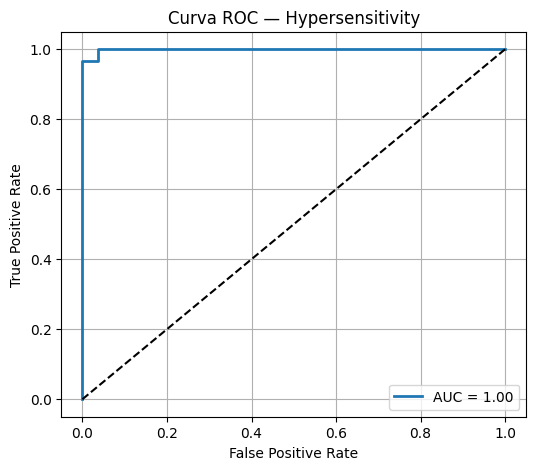

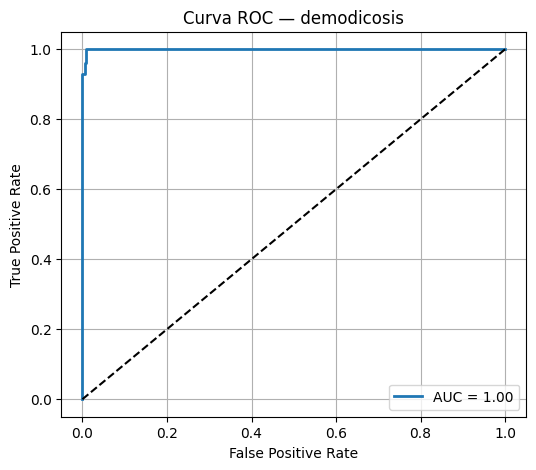

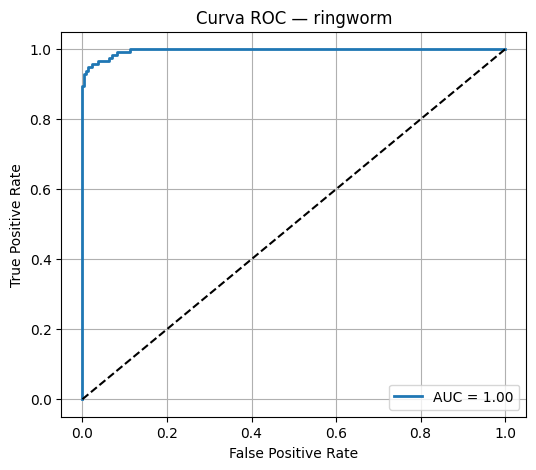

In [28]:

#Curvas ROC por cada Clase

import numpy as np
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt
import os

# Crear carpeta para guardar las imágenes (opcional)
os.makedirs("roc_images", exist_ok=True)

# Binarizar etiquetas para ROC one-vs-rest
y_test_bin = label_binarize(all_labels, classes=list(range(NUM_CLASSES)))
all_probs = np.array(all_probs)

for i in range(NUM_CLASSES):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], all_probs[:, i])
    roc_auc = auc(fpr, tpr)

    plt.figure(figsize=(6, 5))
    plt.plot(fpr, tpr, lw=2, label=f"AUC = {roc_auc:.2f}")
    plt.plot([0, 1], [0, 1], "k--")

    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title(f"Curva ROC — {class_names[i]}")
    plt.legend(loc="lower right")
    plt.grid(True)

    # Guardar cada imagen (opcional)
    plt.savefig(f"roc_images/ROC_{class_names[i]}.png", dpi=120)

    plt.show()

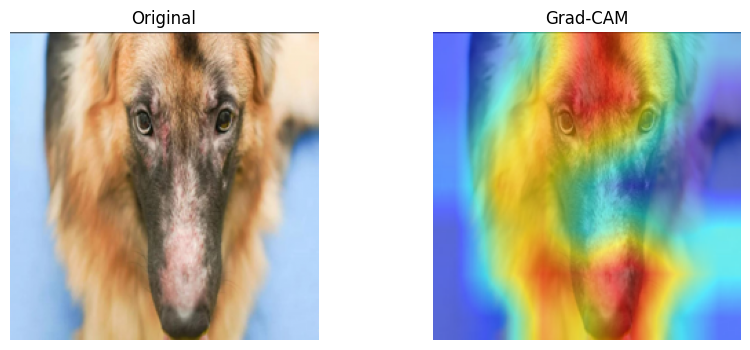

In [25]:
#16. Grad-CAM
!pip install grad-cam

from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

def gradcam_image(img_path):
    img = Image.open(img_path).convert("RGB").resize((224,224))
    img_np = np.array(img)/255.0

    tensor = val_test_transforms(img).unsqueeze(0).to(device)
    target_layer = model.layer4[-1]

    cam = GradCAM(model=model, target_layers=[target_layer])
    grayscale_cam = cam(input_tensor=tensor, targets=[ClassifierOutputTarget(0)])[0]

    cam_img = show_cam_on_image(img_np, grayscale_cam, use_rgb=True)
    return img_np, cam_img

img_np, cam = gradcam_image("/content/ejemplo.jpg")

plt.figure(figsize=(10,4))
plt.subplot(121); plt.imshow(img_np); plt.title("Original"); plt.axis("off")
plt.subplot(122); plt.imshow(cam); plt.title("Grad-CAM"); plt.axis("off")
plt.show()


In [26]:
#17. Guardar modelo + mapping
torch.save(model.state_dict(), "/content/drive/MyDrive/diplomado/model_final_resnet50.pth")

import json
with open("/content/drive/MyDrive/diplomado/class_to_idx.json", "w") as f:
    json.dump(train_ds.class_to_idx, f)
